# III. Fundamentos del Modelamiento Predictivo
# Capítulo 9 - Modelos de Regresión (Ejercicios)

<div style="border-top: 20px solid #b6effb; border-bottom: 20px solid #b6effb; background-color: #cff4fc; color: #055160;">

En los siguientes ejercicios se pretende que conozcas en mayor detalle el funcionamiento detrás de la **validación cruzada**, y cómo podemos utilizar la misma como herramienta para la evaluación de modelos de regresión mediante *criterios de cordura*.

En este sentido, iniciaremos desarrollando un modelo predictivo con el algoritmo de *regresión lineal* para dar atención a un caso práctico, y a partir de allí utilizaremos validación cruzada para estimar su rendimiento. A continuación veremos como generar modelos *dummy* para este tipo de aprendizaje computacional contra los cuales contrastar esta asertividad.

Para alcanzar conclusiónes técnicamente adecuadas, realizemos pruebas de hipótesis que nos permitan establecer inferencias respecto a qué tan adecuado es un modelo predictivo.

</div>

## Entendimiento del contexto

Viña Concha y Toro es una de las empresas más reconocidas a nivel mundial en la industria vinícola. Fundada en 1883 en la zona centro sur de Chile, cuenta con más de un siglo de experiencia en la fabricación de vinos de alta calidad que se distribuyen en comercios minoristas y de especialidad. Entre sus principales marcas destacan Casillero del Diablo, Marqués de Casa Concha y Don Melchor, y al poseer viñedos en Chile, Argentina y California, es capaz de ofrecer una amplia variedad de productos de distintas características henológicas.  

Actualmente, la empresa se encuentra en proceso de implementar herramientas tecnológicas que le permitan adaptar de mejor manera sus operaciones a las dinámicas competitivas actuales. Entre estas iniciativas te han contratado como científico de datos para desarrollar un un modelo predictivo capaz de estimar el grado alcohólico de sus productos mediante mediciones registradas por los especialistas. Al respecto, conviene que sepas que una vez que el vino ha pasado un tiempo pertinente en la barrica, los mencionados especialistas catan el producto, y entre otras características determinan su índice de acidez y su densidad. 

Tu objetivo por tanto será desarrollar este modelo y evaluar si los resultados capaces de obtener son suficientemente asertivos. Si en efecto lo son, entonces será viable incorporar sus predicciones en el proceso productivo del fabricante, agilizando con esto el trabajo del laboratorio y la distribución de productos para su posterior venta.

## Entendimiento de los datos

### Ejercicio 1

Carga las librerías que te permitan manipular y visualizar datos, así como aquella que sirva para ejecutar la prueba U de Mann Witney. Además importa el módulo `metrics` y la clase `LinearRegression` de **scikit-learn**.

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.linear_model import LinearRegression

La empresa ha compartido contigo información en el archivo llamado [wines.csv]("../datasets/wines.csv"), que debes cargarlo y mirar su estructura.

In [2]:
# Cargar dataset
df_wines = pd.read_csv("../datasets/wines.csv")

# Mostrar estructura de los datos
df_wines.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   acidity          1599 non-null   float64
 1   specific_volume  1599 non-null   float64
 2   alcohol_level    1599 non-null   float64
dtypes: float64(3)
memory usage: 37.6 KB


Este dataset contiene 1,599 observaciones asociadas a distintas mediciones realizadas en vinos, con el siguiente detalle:

| Columna | Descripción |
| ---- | ---- |
| acidity | Nivel de acidez registrado por el henólogo que ejecutó la cata. |
| specific_volume | Índicador de densidad registrado por el henólogo. |
| alcohol_level | Grado alcohólico registrado por el laboratorio de la compañía para el vino. |

### Ejercicio 2

Explora el dataset generando una muestra del mismo y un resumen estadístico de sus variables.

In [3]:
# Generar muestra de datos
df_wines.sample(10)

,acidity,specific_volume,alcohol_level
266,0.362390,1.005328,11.379502
473,0.534071,1.004520,10.831355
19,0.234013,1.004248,13.161745
1098,0.645009,1.003915,9.495988
291,0.658553,1.004016,11.276252
364,0.427375,1.003613,11.064006
862,0.712129,0.998602,9.894338
1533,1.016231,1.002607,8.972650
533,0.635346,1.001402,10.678982
451,0.534958,1.004682,10.867578


In [4]:
# Mirar distribucion de variables
df_wines.describe().round(3)

,acidity,specific_volume,alcohol_level
count,1599.000,1599.000,1599.000
mean,0.653,1.003,10.288
std,0.179,0.002,1.084
min,0.124,0.996,8.271
25%,0.529,1.002,9.394
50%,0.648,1.003,10.025
75%,0.788,1.004,10.955
max,1.035,1.010,14.894


Calcula la correlación entre las variables.

In [5]:
# Calcular correlación entre variables
print(df_wines.corr(method = "spearman").round(3))

                 acidity  specific_volume  alcohol_level
acidity            1.000           -0.297         -0.552
specific_volume   -0.297            1.000          0.457
alcohol_level     -0.552            0.457          1.000


In [6]:
# Calcular correlación lineal entre variables
print(df_wines.corr(method = "pearson").round(3))

                 acidity  specific_volume  alcohol_level
acidity             1.00           -0.320         -0.600
specific_volume    -0.32            1.000          0.493
alcohol_level      -0.60            0.493          1.000


Si todo fue hecho correctamente, notarás que existe una correlación lineal significativa entre la acidez y la densidad con la variable objetivo. Esto facilitará la creación de un modelo con el algoritmo de *regresión lineal* utilizando estos atributos.

## Creación y evaluación de modelo con validación cruzada

### Ejercicio 1

Separa los artributos de la variable objetivo.

In [7]:
X = df_wines.drop(columns = "alcohol_level")
y = df_wines["alcohol_level"]

En este caso práctico vamos a ejecutar una validación cruzada sin el uso de funciones preconstruidas de **scikit-learn**. Por esta razón, empecemos definiendo 10 grupos de validación mediante la aplicación de la función `np.random.choice`. Crea un arreglo que contenga la misma cantidad de elementos que observaciones del dataset, y donde cada uno de ellos se correponda con un número entero entre 1 y 10. 

In [8]:
np.random.seed(123)
folds = np.random.choice(range(1,11), size = len(y), replace = True)
np.unique(folds, return_counts = True)

(array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10]),
 array([162, 166, 149, 163, 169, 154, 157, 174, 150, 155]))

Para dar sentido a lo realizado, nota que el $i$-ésimo elemento de este arreglo nos indica el grupo de validación al cual se corresponde la observación $i$ de nuestros datos.

Escoge el primero de estos grupos definiendo la variable `f = 1`. Usa esta variable y el arreglo para particionar el dataset tal que el grupo 1 sea el conjunto de prueba, y todos los demás sean el conjunto de entrenamiento.

In [9]:
f = 1
X_train = X.iloc[np.where(folds != f)]
y_train = y.iloc[np.where(folds != f)]
X_test = X.iloc[np.where(folds == f)]
y_test = y.iloc[np.where(folds == f)]

Crea y entrena un modelo con los datos de entrenamiento.

In [10]:
modelo = LinearRegression(fit_intercept = True)
modelo.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


Evalúa el rendimiento del modelo en el conjunto de prueba calculando el coeficiente de determinación (R2) y el error porcentual absoluto medio (MAPE). Para este último puedes utilizar la función `metrics.mean_absolute_percentage_error`.

In [11]:
# Validar rendimiento del modelo
y_pred = modelo.predict(X_test)

r2 = metrics.r2_score(y_test, y_pred)
print(f"R2 en prueba para fold {f}: {r2:.1%}")

R2 en prueba para fold 1: 51.3%


In [12]:
mape = metrics.mean_absolute_percentage_error(y_test, y_pred)
print(f"MAPE en prueba para fold {f}: {mape:.1%}")

MAPE en prueba para fold 1: 5.9%


<div class="alert alert-info">

El **MAPE** es otra médida para evaluar el rendimiento del modelo y se interpeta como el promedio de errores absolutos entre valores predichos ($y_{pred}$) y reales observados ($y$) de la variable objetivo, relativos a los segundos. Su fórmula se describe a continuación:

$$ MAPE = \frac{1}{n}\times \sum_n \frac{|y - y_{pred}|}{y} $$

donde $n$ es la cantidad de obsrvaciones evaluadas.

</div>

### Ejercicio 2

Repitamos el procedimiento de particionar los datos, crear y entrenar un modelo, y evaluarlo. Solamente que ahora tomando como referencia cada uno de los grupos creados. Crea por tanto un bucle `for` donde se ejecute este proceso y guarda los resultados de R2 y MAPE de cada iteración en listas llamadas `r2_r_cv` y `mape_r_cv` respectivamente.

In [13]:
# Crear listas para guardar metricas
r2_r_cv = []
mape_r_cv = []

print("VALIDACION CRUZADA PARA MODELO REG LIN")
print("="*40)
print()
for f in range(1,11):

    # Particionar datos
    X_train = X.iloc[np.where(folds != f)]
    y_train = y.iloc[np.where(folds != f)]
    X_test = X.iloc[np.where(folds == f)]
    y_test = y.iloc[np.where(folds == f)]

    #Crear y entrenar modelo
    modelo = LinearRegression(fit_intercept = True)
    modelo.fit(X_train, y_train)

    #Evaluar resultados
    y_pred = modelo.predict(X_test)
    r2 = metrics.r2_score(y_test, y_pred)
    r2_r_cv.append(r2)
    mape = metrics.mean_absolute_percentage_error(y_test, y_pred)
    mape_r_cv.append(mape)
    print(f"R2 en prueba para fold {f}: {r2:.1%}")
    print(f"MAPE en prueba para fold {f}: {mape:.1%}")
    print()

VALIDACION CRUZADA PARA MODELO REG LIN

R2 en prueba para fold 1: 51.3%
MAPE en prueba para fold 1: 5.9%

R2 en prueba para fold 2: 45.0%
MAPE en prueba para fold 2: 6.7%

R2 en prueba para fold 3: 37.0%
MAPE en prueba para fold 3: 6.6%

R2 en prueba para fold 4: 51.1%
MAPE en prueba para fold 4: 5.7%

R2 en prueba para fold 5: 46.9%
MAPE en prueba para fold 5: 5.8%

R2 en prueba para fold 6: 39.1%
MAPE en prueba para fold 6: 6.1%

R2 en prueba para fold 7: 54.6%
MAPE en prueba para fold 7: 6.1%

R2 en prueba para fold 8: 37.4%
MAPE en prueba para fold 8: 6.4%

R2 en prueba para fold 9: 40.4%
MAPE en prueba para fold 9: 6.2%

R2 en prueba para fold 10: 47.1%
MAPE en prueba para fold 10: 6.0%



Acabamos de realizar una validación cruzada sin el uso de funciones de **scikit-learn**.

### Ejercicio 3

Visualiza el comportamiento de los diez valores de R2 obtenidos.

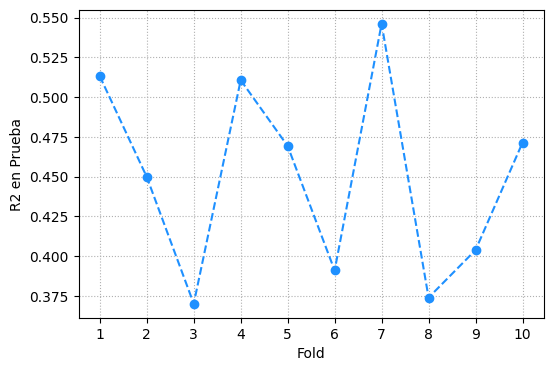

In [14]:
plt.figure(figsize = [6,4])
plt.plot(
    r2_r_cv,
    color = "dodgerblue",
    marker = "o",
    linestyle = "--"
)
plt.xlabel("Fold")
plt.ylabel("R2 en Prueba")
plt.xticks(ticks = range(10), labels = range(1,11))
plt.grid(linestyle = ":")
plt.show()

Resumamos estos resultados mediante un intervalo de confianza. Utilizando el criterio *3-sigma* establece el rango en el que potencialmente podría encontrars este indicador con una confiabilidad de aproximadamante 99%.

In [15]:
lim_inf = np.mean(r2_r_cv) - 3 * np.std(r2_r_cv) 
lim_sup = np.mean(r2_r_cv) + 3 * np.std(r2_r_cv) 
print(f"Intervalo R2 con criterio 3-sigma: [{lim_inf:.1%}, {lim_sup:.1%}]")

Intervalo R2 con criterio 3-sigma: [27.1%, 62.9%]


Visualiza ahora el comportamiento del MAPE obtenido luego de la validación cruzada y obtén su correspondiente intervalo de confianza.

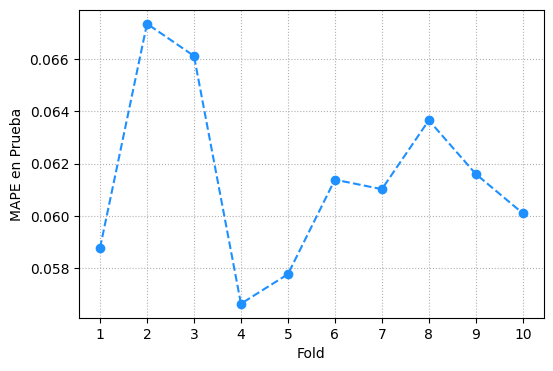

In [16]:
# Visualizar comportamiento de mape
plt.figure(figsize = [6,4])
plt.plot(
    mape_r_cv,
    color = "dodgerblue",
    marker = "o",
    linestyle = "--"
)
plt.xlabel("Fold")
plt.ylabel("MAPE en Prueba")
plt.xticks(ticks = range(10), labels = range(1,11))
plt.grid(linestyle = ":")
plt.show()

In [17]:
# Definir intervalo de mape por criterio 3-sigma
lim_inf = np.mean(mape_r_cv) - 3 * np.std(mape_r_cv) 
lim_sup = np.mean(mape_r_cv) + 3 * np.std(mape_r_cv) 
print(f"Intervalo MAPE con criterio 3-sigma: [{lim_inf:.1%}, {lim_sup:.1%}]")

Intervalo MAPE con criterio 3-sigma: [5.2%, 7.1%]


Gracias a la validación cruzada hemos sido capaces de generar una estimación de los niveles de rendimiento que el modelo alcanzaría si es implementado en los procesos operativos de la empresa. A continuación veremos si este modelo es suficientemente asertivo comparando sus resultados con modelos *dummy* que establezcan un criterio de cordura.

## Criterios de cordura para evaluación de asertividad

### Ejercicio 1

Si nos ponemos a pensar, una línea base que podría servir para la creación de un modelo *dummy* consiste en generar predicciones basadas en la centralidad observada de la variable objetivo. De cualquier manera, la centralidad es una representación del comportamiento típico de los datos, y por ende puede servir como un valor probable que tomen nuevas observaciones.

Sin embargo, surge la pregunta de cuál estadístico de centralidad deberíamos considerar. Para poder dar una respuesta, en primer lugar conveiene estudiar visualmente la distribución de la variable objetivo. Hazlo mediante la generación de un histograma.

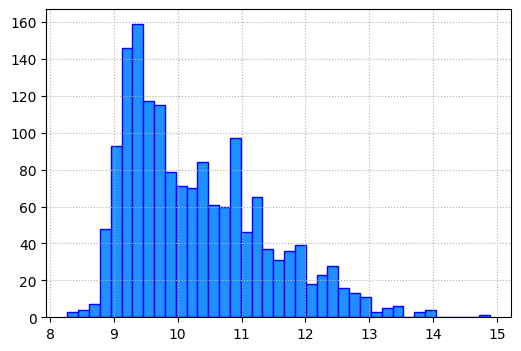

In [18]:
plt.figure(figsize = [6,4])
plt.hist(
    y,
    bins = int(np.sqrt(len(y))),
    color = "dodgerblue",
    edgecolor = "blue"   
)
plt.grid(linestyle = ":")
plt.show()

En vista que existe un sesgo positivo, el uso de la media podría tender a sesgar los resultados. Por tanto utilicemos la mediana como estadístico de referencia.

Calcula este indicador para la variable objetivo y genera predicciones en la que para todos los casos se alcance este valor.

In [19]:
med = np.median(y)
y_pred = [med for v in y]

Evalúa el rendimiento de este modelo *dummy* calculando el R2 y el MAPE.

In [20]:
# Evaluar rendimiento de modelo dummy
r2_d = metrics.r2_score(y, y_pred)
mape_d = metrics.mean_absolute_percentage_error(y, y_pred)
print(f"R2 con modelo dummy: {r2_d:.1%}")
print(f"MAPE con modelo dummy: {mape_d:.1%}")

R2 con modelo dummy: -5.9%
MAPE con modelo dummy: 8.2%


<div class="alert alert-info">

Cuando calculamos el coeficiente de determinación con un modelo *dummy* de mediana, y con una variable que presenta sesgo positivo, el resultado obtenido siempre será negativo. La respuesta de esto surge de la fórmula de este indicador. Si la recuerdas, la misma se definía por 

$$ R^2 = 1 - \frac{\sum_n (y - y_{pred})^2}{\sum_n (y - \bar y)^2}$$

dado que se cumple que $y_{pred} = m$ (donde $m$ es la mediana), se tiene que

$$ y - y_{pred} = y - m > y - \bar y $$

$$ \implies \frac{\sum_n (y - y_{pred})^2}{\sum_n (y - \bar y)^2} = \frac{\sum_n (y - m)^2}{\sum_n (y - \bar y)^2} > 1  $$

$$ \implies R^2 = 1 - \frac{\sum_n (y - m)^2}{\sum_n (y - \bar y)^2} < 1 $$

</div>

### Ejercicio 2

Utiliza la lógica del ejercicio pasado para implementar una validación cruzada del modelo *dummy* con mediana. Guarda los R2 y los MAPE de cada iteración en listas llamadas `r2_d_cv` y `mape_d_cv`.

In [21]:
r2_d_cv = []
mape_d_cv = []
print("VALIDACION CRUZADA PARA MODELO DUMMY")
print("="*40)
print()
for f in range(1,11):
    X_train = X.iloc[np.where(folds != f)]
    y_train = y.iloc[np.where(folds != f)]
    X_test = X.iloc[np.where(folds == f)]
    y_test = y.iloc[np.where(folds == f)]
    med = np.median(y_train)
    y_pred = [med for v in y_test]
    r2 = metrics.r2_score(y_test, y_pred)
    r2_d_cv.append(r2)
    mape = metrics.mean_absolute_percentage_error(y_test, y_pred)
    mape_d_cv.append(mape)
    print(f"R2 en prueba para fold {f}: {r2:.1%}")
    print(f"MAPE en prueba para fold {f}: {mape:.1%}")
    print()

VALIDACION CRUZADA PARA MODELO DUMMY

R2 en prueba para fold 1: -5.0%
MAPE en prueba para fold 1: 8.0%

R2 en prueba para fold 2: -8.1%
MAPE en prueba para fold 2: 8.8%

R2 en prueba para fold 3: -1.9%
MAPE en prueba para fold 3: 8.3%

R2 en prueba para fold 4: -15.7%
MAPE en prueba para fold 4: 8.8%

R2 en prueba para fold 5: -2.0%
MAPE en prueba para fold 5: 7.6%

R2 en prueba para fold 6: -3.8%
MAPE en prueba para fold 6: 7.9%

R2 en prueba para fold 7: -3.7%
MAPE en prueba para fold 7: 8.5%

R2 en prueba para fold 8: -14.4%
MAPE en prueba para fold 8: 8.4%

R2 en prueba para fold 9: -3.0%
MAPE en prueba para fold 9: 7.7%

R2 en prueba para fold 10: -7.0%
MAPE en prueba para fold 10: 8.0%



Calcula intervalos de confianza con el criterio 3-sigma para las métricas de rendimiento obtenidas en la validación cruzada del modelo *dummy*.

In [22]:
# Definir intervalo de r2 por criterio 3-sigma
lim_inf = np.mean(r2_d_cv) - 3 * np.std(r2_d_cv) 
lim_sup = np.mean(r2_d_cv) + 3 * np.std(r2_d_cv) 
print(f"Intervalo R2 con criterio 3-sigma (Modelo Dummy): [{lim_inf:.1%}, {lim_sup:.1%}]")

Intervalo R2 con criterio 3-sigma (Modelo Dummy): [-20.6%, 7.7%]


In [23]:
# Definir intervalo de mape por criterio 3-sigma
lim_inf = np.mean(mape_d_cv) - 3 * np.std(mape_d_cv) 
lim_sup = np.mean(mape_d_cv) + 3 * np.std(mape_d_cv) 
print(f"Intervalo MAPE con criterio 3-sigma (Modelo Dummy): [{lim_inf:.1%}, {lim_sup:.1%}]")

Intervalo MAPE con criterio 3-sigma (Modelo Dummy): [7.0%, 9.4%]


Vistos estos intervalos, parece que nuestro modelo con *regresión lineal* tiene una capacidad predictiva mayor frente a un modelo que utilice un valor referencial típico.

<div class="alert alert-info">

Si en adelante deseas implementar automáticamente este modelo *dummy* mediante **scikit-learn**, utiliza la clase `DummyRegressor`. A continuación el código referencial para su utilización:

```py
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy = "median")
```

Si en alguna circunstancia deseas aplicar la media como referencia del modelo, cambia el argumento `strategy` a la alternativa "mean".

</div>

### Ejercicio 3

Otro criterio de cordura que podríamos utilizar está asociado a identificar si el aprendizaje y los resultados de un modelo se asocian con factores vinculados a los atributos, o si por el contrario responden a un aspecto puramente aleatorio. Para ello, conviene crear los denominados **modelos con permutación** en los cuales "mezclamos" la información asociada a la variable objetivo, y a partir de allí ejecutamos un algoritmo de interés.

Si ante esta permutación se evidencian resultados similares, entonces se concluye que el modelo a implementar no ha tenido un aprendizaje acorde a la realidad de los atributos y que su rendimiento se explica por un simple componente aleatorio.

Para construir este criterio de cordura, utiliza la función `np.random.permutation` para crear una nueva variable objetivo "mezclada" llamada `y_permutada`. 

In [24]:
np.random.seed(123)
y_permutada = np.random.permutation(y)

Ejecuta una validación cruzada de un modelo con *regresión lineal* en el que utilices esta variable objetivo mezclada. Guarda las métricas de rendimiento obtenida en las listas `r2_p_cv` y `mape_p_cv`. 

In [25]:
r2_p_cv = []
mape_p_cv = []
print("VALIDACION CRUZADA PARA MODELO CON PERMUTACION")
print("="*40)
print()
for f in range(1,11):
    X_train = X.iloc[np.where(folds != f)]
    y_train = y_permutada[np.where(folds != f)]
    X_test = X.iloc[np.where(folds == f)]
    y_test = y_permutada[np.where(folds == f)]
    modelo = LinearRegression(fit_intercept = True)
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    r2 = metrics.r2_score(y_test, y_pred)
    r2_p_cv.append(r2)
    mape = metrics.mean_absolute_percentage_error(y_test, y_pred)
    mape_p_cv.append(mape)
    print(f"R2 en prueba para fold {f}: {r2:.1%}")
    print(f"MAPE en prueba para fold {f}: {mape:.1%}")
    print()

VALIDACION CRUZADA PARA MODELO CON PERMUTACION

R2 en prueba para fold 1: -0.9%
MAPE en prueba para fold 1: 8.2%

R2 en prueba para fold 2: -0.8%
MAPE en prueba para fold 2: 8.3%

R2 en prueba para fold 3: -1.4%
MAPE en prueba para fold 3: 9.0%

R2 en prueba para fold 4: -0.5%
MAPE en prueba para fold 4: 8.4%

R2 en prueba para fold 5: -0.7%
MAPE en prueba para fold 5: 8.4%

R2 en prueba para fold 6: -0.3%
MAPE en prueba para fold 6: 8.8%

R2 en prueba para fold 7: -1.6%
MAPE en prueba para fold 7: 8.6%

R2 en prueba para fold 8: -1.1%
MAPE en prueba para fold 8: 8.9%

R2 en prueba para fold 9: -0.8%
MAPE en prueba para fold 9: 8.8%

R2 en prueba para fold 10: -0.5%
MAPE en prueba para fold 10: 8.5%



Con las listas resultantes de tu validación cruzada, calcula intervalos de confianza 3-sigma para los indicadores de evaluación que estamos comparando.

In [26]:
# Definir intervalo de r2 por criterio 3-sigma
lim_inf = np.mean(r2_p_cv) - 3 * np.std(r2_p_cv) 
lim_sup = np.mean(r2_p_cv) + 3 * np.std(r2_p_cv) 
print(f"Intervalo R2 con criterio 3-sigma (Permutacion): [{lim_inf:.1%}, {lim_sup:.1%}]")

Intervalo R2 con criterio 3-sigma (Permutacion): [-2.0%, 0.3%]


In [27]:
# Definir intervalo de mape por criterio 3-sigma
lim_inf = np.mean(mape_p_cv) - 3 * np.std(mape_p_cv) 
lim_sup = np.mean(mape_p_cv) + 3 * np.std(mape_p_cv) 
print(f"Intervalo MAPE con criterio 3-sigma (Permutacion): [{lim_inf:.1%}, {lim_sup:.1%}]")

Intervalo MAPE con criterio 3-sigma (Permutacion): [7.8%, 9.4%]


Ante estos resultados, parece existir evidencia que el modelo inicial que creamos pronostica en base a los atributos el dataset y no a factores exógenos a los observados.

### Ejercicio 4

Parece que el modelo creado para Viña Concha y Toro supera los criterios de cordura expuestos, lo cual da cuenta de su adecuada capacidad predictiva y asertividad. Sin embargo, para tener una completa certeza de lo expuesto conviene aplicar nuestros conocimientos de inferencia. 

Dado que para cada modelo y para cada métrica solamente contamos con 10 observaciones a partir de la validación cruzada, aplica una prueba U de Mann-Whitney en la que evalúes lo siguiente:

<div class="alert alert-success">

| Hipótesis | Postulado |
| ---- | ---- |
| Nula | El valor esperado del R2 del modelo es IGUAL al del modelo *dummy*. |
| Alternativa | El valor esperado del R2 del modelo es MAYOR al del modelo *dummy*. |

</div>

In [28]:
p_val = st.mannwhitneyu(r2_r_cv, r2_d_cv, alternative = "greater").pvalue
print(f"Valor p: {p_val:.1%}")

Valor p: 0.0%


Repite la prueba de hipótesis pero ahora contrasta con el modelo con permutaciones.

In [29]:
p_val = st.mannwhitneyu(r2_r_cv, r2_p_cv, alternative = "greater").pvalue
print(f"Valor p: {p_val:.1%}")

Valor p: 0.0%


Evalúa ahora la siguiente hipótesis:

<div class="alert alert-success">

| Hipótesis | Postulado |
| ---- | ---- |
| Nula | El valor esperado del MAPE del modelo es IGUAL al del modelo *dummy*. |
| Alternativa | El valor esperado del MAPE del modelo es MENOR al del modelo *dummy*. |

</div>

In [30]:
# Realizar prueba para verificar que mape de modelo de regresion es menor a dummy
p_val = st.mannwhitneyu(mape_r_cv, mape_d_cv, alternative = "less").pvalue
print(f"Valor p: {p_val:.1%}")

Valor p: 0.0%


Nuevamente repite la prueba pero ahora contra el modelo con permutaciones.

In [31]:
# Realizar prueba para verificar que mape de modelo de regresion es menor a modelo con permutacion
p_val = st.mannwhitneyu(mape_r_cv, mape_p_cv, alternative = "less").pvalue
print(f"Valor p: {p_val:.1%}")

Valor p: 0.0%


En efecto, se ha confirmado que el modelo a entregar a la empresa tiene un grado de asertividad pertinente y puede implementarse para aportar en la mejora de procesos y distribución.